# Exercise 4: Running a Custom-Trained YOLO26 Flag Model on New Photos
DATA 78000, Computer Vision assignment

Based on `yolo/yolo26_custommodel.py`. It loads a custom YOLO26 checkpoint, runs it on one debug image, draws the boxes, and shows the result in a pop-up window.

The checkpoints were trained. There are 228 classes: countries and territories, plus `Pride`, `European Union`, `United Nations` and a catch-all `Others`.

| run | model size | epochs | validation mAP50 |
|---|---|---|---|
| `takingstock_flag_multi_v1_yolo26m` | medium | 92 | **0.96** |
| `takingstock_flags_nov9_yolo26n` | nano | 33 | 0.32 |


- **Batch pipeline** over all 1,797 `images_123rf` photos, from a *different stock agency* (123RF) than the training data. It writes a CSV, and saves example images in one folder per predicted country.
- **How good is 0.96 really?** The images have no labels, but the filenames do ("...holding-usa-flag..."). Filename keywords serve as a rough answer key, then a hand spot-check of 48 random images, then a check against YOLOe from Exercise 3.
- **Medium vs nano:** the same images through the less-trained model.

Outputs (in `computer-vision/outputs/`):
- `ex4_flags.csv`: one row per detection (images with none get one empty row)
- `ex4_flags_nano.csv`: the same for the nano model
- `ex4_by_country/<country>/`: up to 8 annotated examples per predicted country
- `ex4_spotcheck_sheet_*.jpg`: contact sheets for the hand check; labels are in `assignment/ex4_spotcheck_labels.csv`

## 1. Setup and the fixed starter

In [1]:
import math
import re
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ultralytics import YOLO

# Walk up from wherever the notebook runs to the folder that contains DATA7800_YOLO
PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "DATA7800_YOLO").exists())
DATA_DIR = PROJECT_DIR / "DATA7800_YOLO"
IMAGE_ROOT = DATA_DIR / "images_123rf"
CV_DIR = PROJECT_DIR / "computer-vision"
OUT_DIR = CV_DIR / "outputs"
ASSIGN_DIR = CV_DIR / "assignment"
CLASS_DIR = OUT_DIR / "ex4_by_country"
CLASS_DIR.mkdir(parents=True, exist_ok=True)

# --- The starter's bug, fixed ---
# Starter:  MODEL_PATH = "next((path for path in MODEL_CANDIDATES if path.exists()), MODEL_CANDIDATES[0])"
# Wrapping it in quotes makes it a plain string, so the expression never runs.
# The starter also listed the nano run first; the medium run is far better (mAP50 0.96 vs 0.32).
MODEL_CANDIDATES = [
    DATA_DIR / "takingstock_flag_multi_v1_yolo26m" / "weights" / "best.pt",   # medium, 0.96
    DATA_DIR / "takingstock_flags_nov9_yolo26n" / "weights" / "best.pt",      # nano, 0.32
]
MODEL_PATH = next((path for path in MODEL_CANDIDATES if path.exists()), MODEL_CANDIDATES[0])
NANO_PATH = MODEL_CANDIDATES[1]

CONF = 0.25          # the starter's confidence cut-off
LIMIT = None         # e.g. 50 while experimenting; None = all 1,797 images
PER_CLASS = 8        # annotated examples saved per predicted country
RERUN = False        # the medium-model batch takes ~1 hour on CPU; reuse the saved CSV unless True

model = YOLO(str(MODEL_PATH))
print("Loaded", MODEL_PATH.relative_to(PROJECT_DIR), "-", len(model.names), "classes")


def list_images(root, limit=None):
    # Same walk as yolo/walk_hashed_directory.py: root/<0-F>/<00-FF>/*.jpg
    paths = sorted(root.glob("*/*/*.jpg"))
    return paths[:limit] if limit else paths


def rel(path):
    return Path(path).relative_to(DATA_DIR).as_posix()


image_paths = list_images(IMAGE_ROOT, LIMIT)
print(len(image_paths), "images")

Loaded DATA7800_YOLO\takingstock_flag_multi_v1_yolo26m\weights\best.pt - 228 classes
1797 images


### Class names need cleaning
The checkpoint's class names are ISO-style ("Bahamas (the)"), and a few were mangled when the dataset was built: the first word of some names is missing. `"States of America (the)"` is the USA, `"Federation (the)"` is presumably the Russian Federation, and `"(the Republic of)"` presumably Korea (South). `Serbia` appears twice. A short display name makes the tables readable. The guesses for the mangled names are checked against the predictions further down.

In [2]:
SHORT = {
    "States of America (the)": "USA",
    "United Kingdom of Great Britain and Northern Ireland (the)": "UK",
    "Federation (the)": "Russia?",
    "(the Republic of)": "South Korea?",
    "Korea (the Democratic People's Republic of)": "North Korea",
    "Congo Congo (the)": "Congo?",
    "Congo (the Democratic Republic of the)": "DR Congo",
    "Netherlands, Kingdom of the": "Netherlands",
    "Tanzania, the United Republic of": "Tanzania",
    "Virgin Islands (British)": "British Virgin Is.",
    "Virgin Islands (U.S.)": "US Virgin Is.",
    "Holy See (the)": "Vatican",
    "Viet Nam": "Vietnam",
    "Lao People's Democratic Republic (the)": "Laos",
}


def short(name):
    # Drop ISO parentheticals such as "(the)" or "(Islamic Republic of)" unless there's a manual fix
    return SHORT.get(name, re.sub(r"\s*\(.*\)$", "", name).strip() or name)


names = {i: short(n) for i, n in model.names.items()}
dupes = pd.Series(list(model.names.values())).value_counts()
print("Duplicate class names:", list(dupes[dupes > 1].index))
print("Odd names:", [n for n in model.names.values() if n.startswith("(") or n.split()[0] in ("States", "Federation", "Congo")])

Duplicate class names: ['Serbia']
Odd names: ['Congo (the Democratic Republic of the)', 'Congo Congo (the)', 'Federation (the)', '(the Republic of)', 'States of America (the)']


## 2. The canonical pattern on one image
The starter's drawing loop, unchanged apart from short names, saving with `cv2.imwrite`, and showing with matplotlib (`cv2.imshow` blocks a notebook).

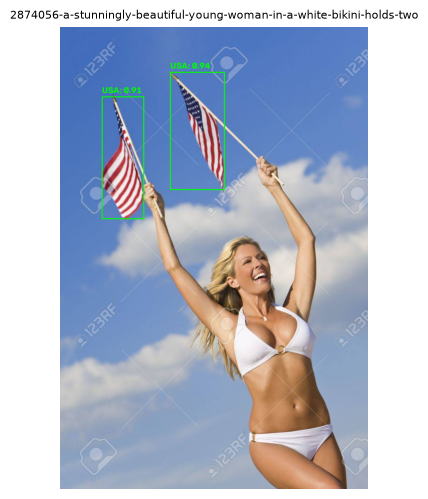

In [3]:
def draw_detections(img, result, names):
    out = img.copy()
    thick = max(2, img.shape[1] // 400)
    for box, cls, score in zip(result.boxes.xyxy, result.boxes.cls, result.boxes.conf):
        x1, y1, x2, y2 = map(int, box)                                   # box corners in pixels
        label = f"{names[int(cls)]}: {float(score):.2f}"                 # class name + confidence
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), thick)
        cv2.putText(out, label, (x1, max(25, y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, thick * 0.4, (0, 255, 0), thick)
    return out


def show(img, title="", size=6):
    plt.figure(figsize=(size, size))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=8)
    plt.axis("off")
    plt.show()


demo = image_paths[1]
result = model.predict(str(demo), conf=CONF, verbose=False)[0]
show(draw_detections(cv2.imread(str(demo)), result, names), demo.name[:70])

## 3. Batch over all 1,797 images
One row per detection, with the starter's fields plus `box_area_pct` (box size as a share of the image), since small flags are a likely failure mode. Images with no detection still get one row with an empty `country`, so "no flag found" is recorded, not lost.

Up to `PER_CLASS` annotated images per predicted country are saved to `ex4_by_country/<country>/`, after the `SAVE_TO_CLASS_FOLDERS` idea in `yolo/draw_yolo_detections.py`.

In [4]:
def run_batch(model, paths, names, save_examples=False):
    rows, saved = [], {}
    for i, path in enumerate(paths, 1):
        result = model.predict(str(path), conf=CONF, verbose=False)[0]
        h, w = result.orig_shape
        boxes = result.boxes
        if len(boxes) == 0:
            rows.append({"image_path": rel(path), "country": None})
        for box, cls, score in zip(boxes.xyxy.tolist(), boxes.cls.tolist(), boxes.conf.tolist()):
            x1, y1, x2, y2 = box
            rows.append({
                "image_path": rel(path), "country": names[int(cls)], "conf": round(score, 3),
                "x1": round(x1), "y1": round(y1), "x2": round(x2), "y2": round(y2),
                "box_area_pct": round((x2 - x1) * (y2 - y1) / (w * h), 4),
            })
        if save_examples and len(boxes):
            top = names[int(boxes.cls[boxes.conf.argmax()])]                # file under the most confident class
            if saved.get(top, 0) < PER_CLASS:
                folder = CLASS_DIR / re.sub(r"[^\w\- ]", "", top)
                folder.mkdir(exist_ok=True)
                cv2.imwrite(str(folder / path.name), draw_detections(result.orig_img, result, names))
                saved[top] = saved.get(top, 0) + 1
        if i % 200 == 0:
            print(f"{i}/{len(paths)}")
    return pd.DataFrame(rows)


csv_path = OUT_DIR / "ex4_flags.csv"
if RERUN or not csv_path.exists():
    det = run_batch(model, image_paths, names, save_examples=True)
    det.to_csv(csv_path, index=False)
else:
    det = pd.read_csv(csv_path)
flags = det.dropna(subset=["country"])
print(f"{len(flags)} detections in {flags.image_path.nunique()} of {det.image_path.nunique()} images")
flags.head()

1606 detections in 929 of 1797 images


,image_path,country,conf,x1,y1,x2,y2,box_area_pct
0,images_123rf/0/00/195392097-pride-lgbtq-and-bl...,Pride,0.778,50.0,160.0,298.0,563.0,0.0885
1,images_123rf/0/00/2874056-a-stunningly-beautif...,USA,0.940,309.0,128.0,462.0,457.0,0.0446
2,images_123rf/0/00/2874056-a-stunningly-beautif...,USA,0.909,117.0,196.0,235.0,540.0,0.0359
8,images_123rf/0/01/167549942-a-portrait-of-a-yo...,UK,0.867,479.0,63.0,624.0,163.0,0.0129
9,images_123rf/0/01/167549942-a-portrait-of-a-yo...,China,0.483,1038.0,352.0,1189.0,470.0,0.0158


## 4. What does it find?

Images with zero detections: 868 (48%)
Distinct countries predicted: 86 of 227


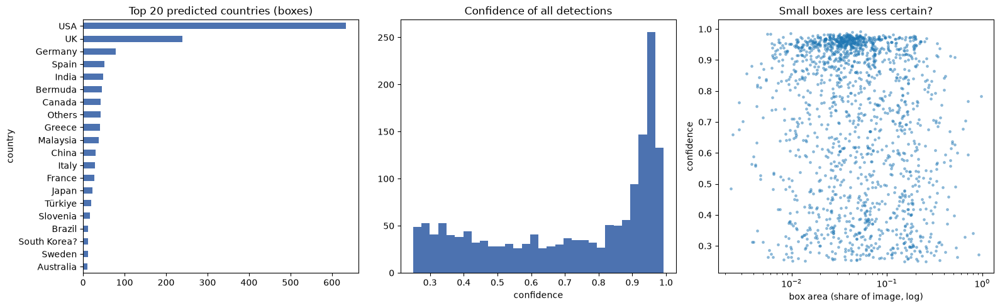

,boxes,images,mean_conf
country,,,
USA,633,434,0.80
UK,240,234,0.68
Germany,78,77,0.74
Spain,51,46,0.70
India,48,36,0.82
Bermuda,46,46,0.54
Others,42,37,0.56
Canada,42,40,0.73
Greece,40,30,0.60


In [5]:
per_image = det.groupby("image_path").country.apply(lambda s: s.notna().sum()).rename("n_flags")
print(f"Images with zero detections: {(per_image == 0).sum()} ({(per_image == 0).mean():.0%})")
print(f"Distinct countries predicted: {flags.country.nunique()} of {len(set(names.values()))}")

top = flags.country.value_counts()
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
top.head(20)[::-1].plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Top 20 predicted countries (boxes)")
axes[1].hist(flags.conf, bins=30, color="#4C72B0")
axes[1].set_title("Confidence of all detections")
axes[1].set_xlabel("confidence")
axes[2].scatter(flags.box_area_pct, flags.conf, s=6, alpha=0.4)
axes[2].set_xscale("log")
axes[2].set_xlabel("box area (share of image, log)")
axes[2].set_ylabel("confidence")
axes[2].set_title("Small boxes are less certain?")
plt.tight_layout()
plt.show()

summary = flags.groupby("country").agg(boxes=("conf", "size"), images=("image_path", "nunique"),
                                       mean_conf=("conf", "mean")).sort_values("boxes", ascending=False)
summary.head(25).round(2)

**Is the US share the photos or the model?** The stock collection was gathered by searching flag terms on an American agency, so a US-heavy result is expected either way. The filename check in section 5 separates the two: if the model also calls *non*-US flags "USA", that's the model.

## 5. A rough answer key from filenames
123RF filenames are the photo's title, for example `...-woman-holding-usa-flag-...`. When a title names one country, that's weak ground truth. Weak, because titles are written for search engines: "African American woman" is not a flag, "english language" photos usually show a UK flag but not always, and a title can name one country while the photo shows several.

US state flags (`...usa-states-flags-on-background-idaho`) get their own group. They aren't among the 228 classes, so the *right* answer is "not USA".

In [6]:
KEYWORDS = {
    "USA": ["usa", "us", "america", "american", "4th", "july"],
    "UK": ["uk", "british", "britain", "england"],
    "Germany": ["german", "germany"],
    "Lithuania": ["lithuanian", "lithuania"],
    "Ukraine": ["ukrainian", "ukraine"],
    "Mexico": ["mexican", "mexico"],
    "Russia?": ["russia", "russian"],
    "Brazil": ["brazil", "brazilian"],
    "India": ["indian", "india"],
    "Italy": ["italian", "italy"],
    "France": ["french", "france"],
    "Canada": ["canada", "canadian"],
    "Pride": ["pride", "lgbt", "lgbtq", "rainbow"],
}


def title_words(path):
    stem = Path(path).stem
    return set(stem.split("-")[1:])                    # drop the numeric stock id


def keyword_countries(path):
    words = title_words(path)
    if "states" in words and "flags" in words and ("usa" in words or "american" in words):
        return ["US states"]
    return [c for c, kws in KEYWORDS.items() if words & set(kws)]


predicted = flags.groupby("image_path").country.apply(set)
rows = []
for path in per_image.index:
    for kc in keyword_countries(path):
        found = predicted.get(path, set())
        rows.append({"image_path": path, "keyword_country": kc, "any_flag": bool(found),
                     "match": kc in found, "predicted": ", ".join(sorted(found))})
kw = pd.DataFrame(rows)


def top_preds(s):
    counts = pd.Series([c for p in s for c in p.split(", ") if c]).value_counts().head(3)
    return ", ".join(f"{c} ({n})" for c, n in counts.items())


kw_table = kw.groupby("keyword_country").agg(
    images=("image_path", "size"),
    found_that_country=("match", "mean"),
    found_any_flag=("any_flag", "mean"),
    most_predicted=("predicted", top_preds),
).sort_values("images", ascending=False)
kw_table.style.format({"found_that_country": "{:.0%}", "found_any_flag": "{:.0%}"})

,images,found_that_country,found_any_flag,most_predicted
keyword_country,,,,
USA,247,80%,83%,"USA (197), UK (16), Others (5)"
US states,142,0%,4%,"USA (5), Australia (1)"
UK,32,78%,88%,"UK (25), USA (9), Germany (3)"
Germany,27,52%,74%,"Germany (14), UK (11), USA (5)"
India,26,88%,100%,"India (23), USA (4), Malaysia (2)"
Mexico,21,14%,48%,"China (4), Mexico (3), India (3)"
Russia?,20,10%,80%,"Slovenia (12), USA (4), Russia? (2)"
Ukraine,17,18%,24%,"Ukraine (3), Slovenia (1), USA (1)"
Italy,14,29%,71%,"Italy (4), UK (4), Germany (3)"


`found_that_country` works as a recall estimate: when the title names a country, how often the model finds that country's flag. It is a *floor*, since some titles name a country that isn't shown. For US states, a high value would be bad, and `most_predicted` shows what the model calls a state flag instead.

US state-flag images: 142
USA          5
Australia    1
Name: count, dtype: int64


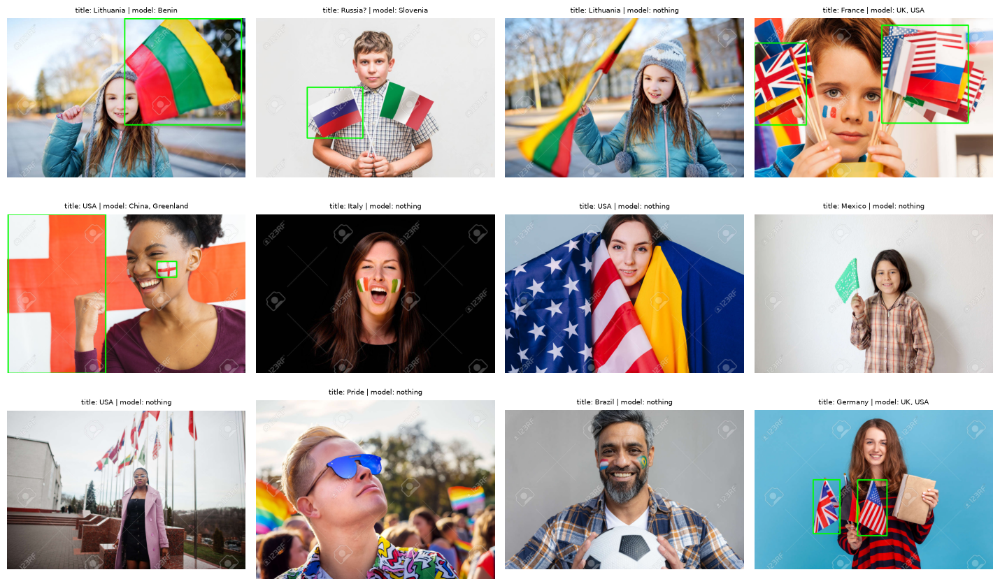

In [7]:
# What does the model call the US state flags, and a sample of where it fails on keyword images
states = kw[kw.keyword_country == "US states"]
print("US state-flag images:", len(states))
print(pd.Series([c for p in states.predicted for c in p.split(", ") if c]).value_counts().head(10))


def contact_sheet(paths, titles, cols=4, size=3.6, save=None):
    paths = list(paths)
    rows_n = math.ceil(len(paths) / cols)
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * size, rows_n * size * 0.8))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, p, t in zip(np.ravel(axes), paths, titles):
        img = cv2.imread(str(DATA_DIR / p))
        boxes = flags[flags.image_path == p]
        for _, b in boxes.iterrows():
            cv2.rectangle(img, (int(b.x1), int(b.y1)), (int(b.x2), int(b.y2)), (0, 255, 0), max(3, img.shape[1] // 250))
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=7)
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=110)
    plt.show()


misses = kw[(kw.keyword_country != "US states") & ~kw.match]
misses = misses.sample(min(12, len(misses)), random_state=78000)
contact_sheet(misses.image_path,
              [f"title: {k} | model: {p or 'nothing'}"[:60] for k, p in zip(misses.keyword_country, misses.predicted)])

## 6. Spot-check: 48 random images by hand
Filenames only cover images that name one country. For an honest error rate, 48 images were drawn at random (seed 78000) and each was labelled by eye:
- **correct**: every box has the right country and no clear national flag was missed
- **wrong_country**: a flag was found but given the wrong country
- **missed**: a clear national flag got no box (or only some flags in the image did)
- **false_positive**: a box on something that isn't a flag
- **no_flag_ok**: no national flag in the photo, and the model correctly found nothing
- **unclear**: flags too small or distant to verify the prediction

An image can have several problems; `verdict` records the worst one, and `note` says what happened. The labels are in `assignment/ex4_spotcheck_labels.csv`. **They are Claude's first-pass labels from the contact sheets and should be spot-checked.**

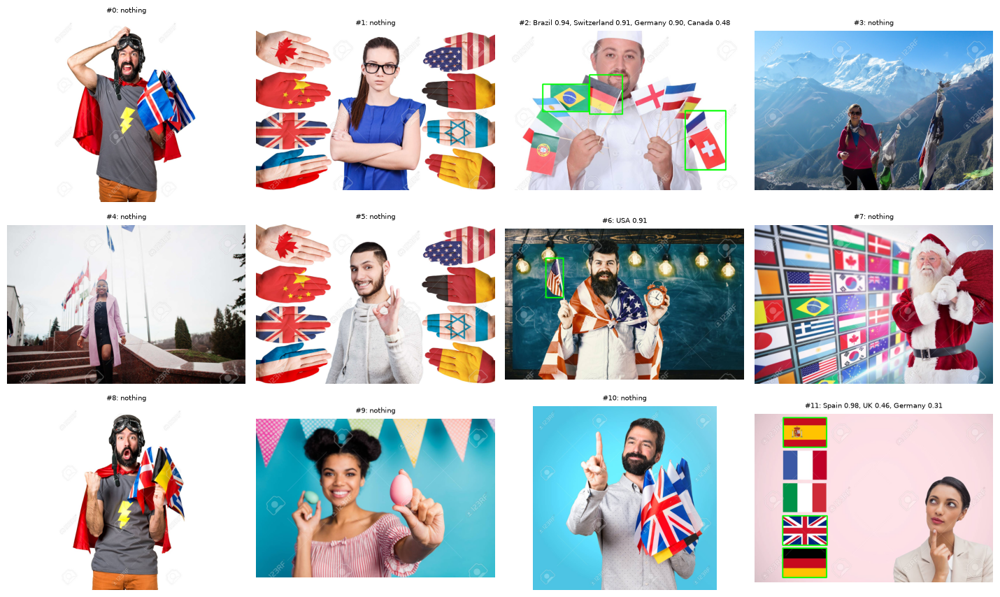

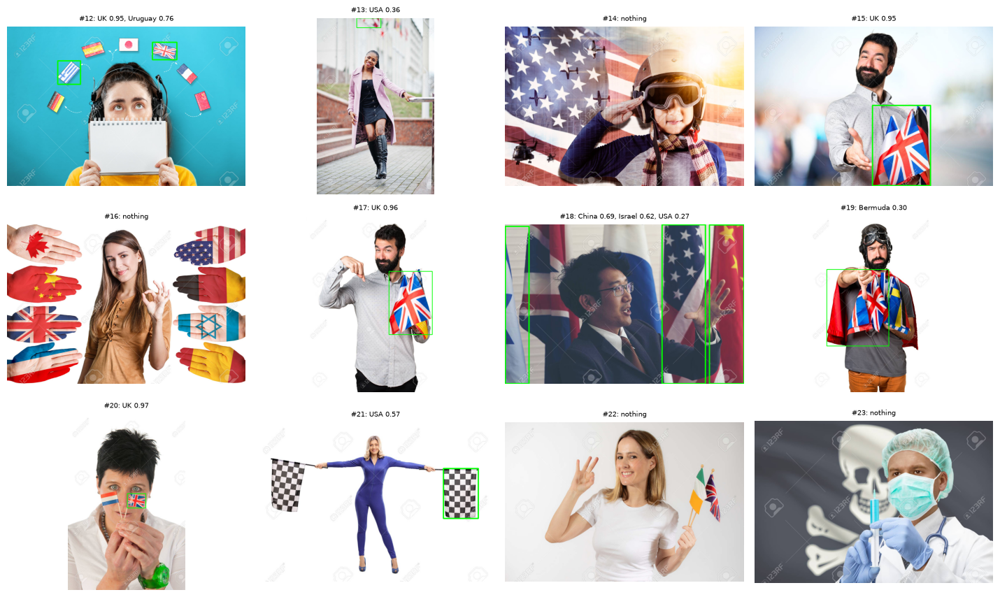

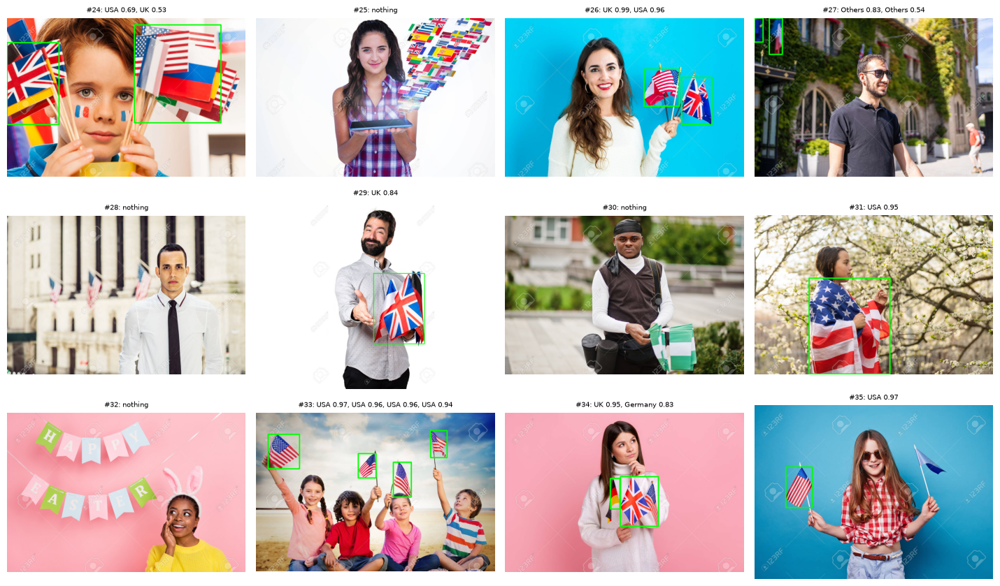

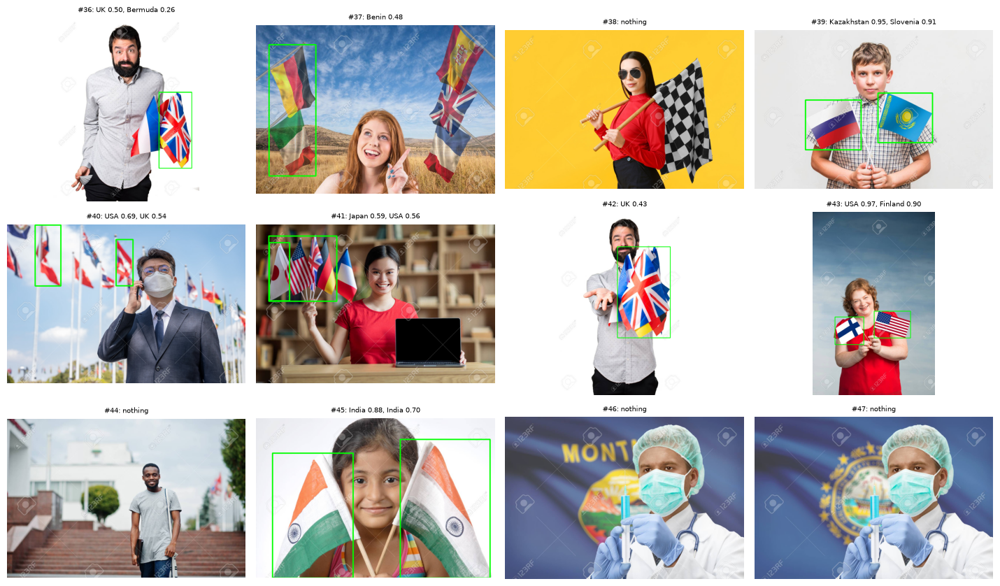

,images
verdict,
missed,22
correct,10
no_flag_ok,7
wrong_country,5
unclear,3
false_positive,1


In [8]:
spot = per_image.sample(min(48, len(per_image)), random_state=78000).index.tolist()
spot_pred = [", ".join(f"{r.country} {r.conf:.2f}" for r in flags[flags.image_path == p].itertuples()) or "nothing"
             for p in spot]
for k in range(4):
    chunk = slice(k * 12, (k + 1) * 12)
    contact_sheet(spot[chunk], [f"#{k * 12 + j}: {t}"[:60] for j, t in enumerate(spot_pred[chunk])],
                  save=OUT_DIR / f"ex4_spotcheck_sheet_{k}.jpg")

labels_path = ASSIGN_DIR / "ex4_spotcheck_labels.csv"
if not labels_path.exists():
    pd.DataFrame({"idx": range(len(spot)), "image_path": spot, "predicted": spot_pred,
                  "verdict": "", "note": ""}).to_csv(labels_path, index=False)
    print("Wrote blank label sheet:", labels_path)
labels = pd.read_csv(labels_path)
assert labels.image_path.tolist() == spot, "label sheet doesn't match this sample"
labels.verdict.value_counts().to_frame("images")

In [9]:
labelled = labels[labels.verdict.notna() & (labels.verdict != "")]
if len(labelled):
    ok = labelled.verdict.isin(["correct", "no_flag_ok"]).mean()
    print(f"Fully right: {ok:.0%} of {len(labelled)} images")
    display(labelled[~labelled.verdict.isin(["correct", "no_flag_ok"])][["idx", "predicted", "verdict", "note"]])

Fully right: 35% of 48 images


,idx,predicted,verdict,note
0,0,nothing,missed,"bundle of hand flags (Iceland, UK, Greece...) ..."
1,1,nothing,missed,flags painted on hands; none found
2,2,"Brazil 0.94, Switzerland 0.91, Germany 0.90, C...",missed,"Brazil, Germany, Switzerland right; England, P..."
4,4,nothing,missed,small distant flags on poles
5,5,nothing,missed,flags painted on hands; none found
6,6,USA 0.91,missed,small USA flag right; the large US flag draped...
7,7,nothing,missed,video-wall collage of dozens of flags; none found
8,8,nothing,missed,"bundle of hand flags (UK, Belgium, Iceland); n..."
10,10,nothing,missed,UK and other flags in hand; nothing found
11,11,"Spain 0.98, UK 0.46, Germany 0.31",missed,"Spain, UK, Germany right; France and Italy missed"


## 7. Cross-check with YOLOe (Exercise 3)
YOLOe was asked for a generic "flag". Where the two disagree, one of them is wrong, and the contact sheets show which.

trained_flag  False  True   All
yoloe_flag                     
False           472   147   619
True            396   782  1178
All             868   929  1797


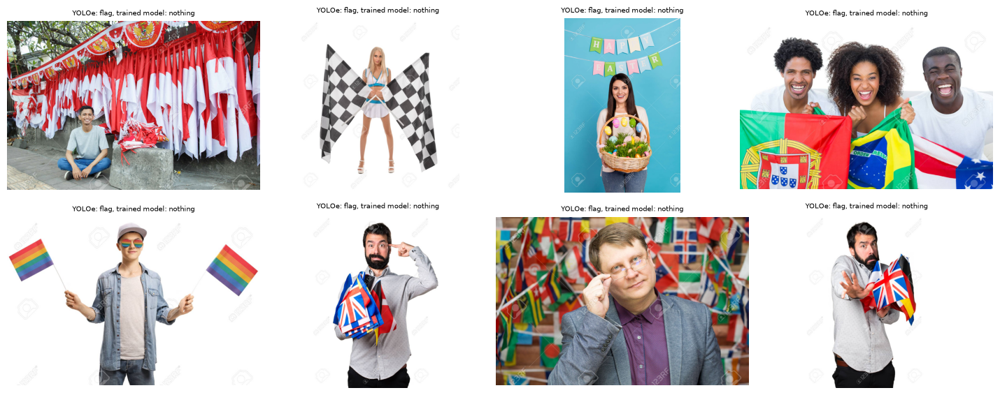

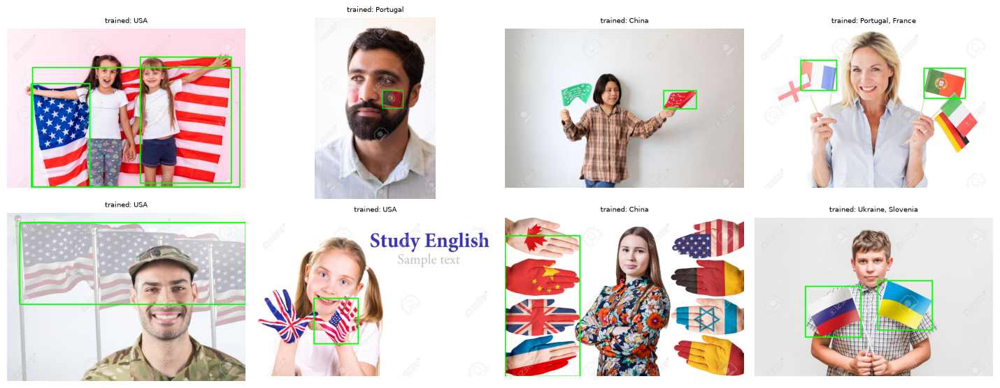

In [10]:
yoloe = pd.read_csv(OUT_DIR / "ex3_yoloe_per_image.csv").set_index("image_path")
both = yoloe.join(per_image)
both["yoloe_flag"] = both.n_flag > 0
both["trained_flag"] = both.n_flags > 0
print(pd.crosstab(both.yoloe_flag, both.trained_flag, margins=True))

only_yoloe = both[both.yoloe_flag & ~both.trained_flag]
only_yoloe = only_yoloe.sample(min(8, len(only_yoloe)), random_state=1).index
contact_sheet(only_yoloe, ["YOLOe: flag, trained model: nothing"] * len(only_yoloe))
only_trained = both[~both.yoloe_flag & both.trained_flag]
if len(only_trained):
    pick = only_trained.sample(min(8, len(only_trained)), random_state=1).index
    contact_sheet(pick, [("trained: " + ", ".join(predicted[p]))[:55] for p in pick])

## 8. Medium vs nano
Same data and classes, a smaller network, fewer epochs (33 vs 92). Validation mAP50 dropped from 0.96 to 0.32. Does it look as bad on new photos?

In [11]:
nano_csv = OUT_DIR / "ex4_flags_nano.csv"
if RERUN or not nano_csv.exists():
    nano = YOLO(str(NANO_PATH))
    nano_det = run_batch(nano, image_paths, {i: short(n) for i, n in nano.names.items()})
    nano_det.to_csv(nano_csv, index=False)
else:
    nano_det = pd.read_csv(nano_csv)

nano_flags = nano_det.dropna(subset=["country"])
nano_pred = nano_flags.groupby("image_path").country.apply(set)
cmp = pd.DataFrame({"medium": predicted, "nano": nano_pred}).reindex(per_image.index)
cmp = cmp.apply(lambda col: col.apply(lambda v: v if isinstance(v, set) else set()))
cmp["same_set"] = cmp.medium == cmp.nano
cmp["overlap"] = [bool(a & b) for a, b in zip(cmp.medium, cmp.nano)]

print(f"Images with any detection: medium {cmp.medium.apply(len).gt(0).mean():.0%}, nano {cmp.nano.apply(len).gt(0).mean():.0%}")
print(f"Same set of countries: {cmp.same_set.mean():.0%} of images; at least one country in common: {cmp.overlap.mean():.0%}")
nano_kw = kw.assign(nano_match=[k in nano_pred.get(p, set()) for p, k in zip(kw.image_path, kw.keyword_country)])
nano_kw.groupby("keyword_country")[["match", "nano_match"]].mean().rename(
    columns={"match": "medium", "nano_match": "nano"}).loc[kw_table.index].style.format("{:.0%}")

Images with any detection: medium 52%, nano 47%
Same set of countries: 50% of images; at least one country in common: 23%


,medium,nano
keyword_country,,
USA,80%,69%
US states,0%,0%
UK,78%,53%
Germany,52%,0%
India,88%,65%
Mexico,14%,0%
Russia?,10%,0%
Ukraine,18%,0%
Italy,29%,0%
